# Giai đoạn 1: Xây dựng và kiểm tra bộ dữ liệu Gaussian 2D
## 1.1. Khởi tạo môi trường và thư viện


In [1]:
import sys
import io
import json
import inspect
import importlib.util
import subprocess
from pathlib import Path

for package in ("numpy", "torch"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import numpy as np
import torch

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert (torch.ones(2, device=device) + 1).tolist() == [2.0, 2.0]

## 1.2. Thiết lập thư mục và cấu hình dữ liệu

Khai báo thư mục dự án, vector trung bình, ma trận hiệp phương sai, miền lấy mẫu và seed. Quy mô dữ liệu gồm 2.000 mẫu train, 400 mẫu validation và 100 mẫu test.

In [2]:
PROJECT_DIR = (Path("/content") if IN_COLAB else Path.cwd()) / "Gaussian2D"
DATA_DIR = PROJECT_DIR / "data"
SRC_DIR = PROJECT_DIR / "src"
for folder in (DATA_DIR, SRC_DIR):
    folder.mkdir(parents=True, exist_ok=True)

MU = np.array([0.0, 0.0], dtype=np.float64)
C = np.array([[0.3, -0.5], [-0.5, 2.0]], dtype=np.float64)
LOW = np.array([-2.0, -4.0])
HIGH = np.array([2.0, 4.0])
ROOT_SEED = 20261024
SPLIT_SIZES = {"train_full": 2000, "val": 400, "test": 100}
SPLIT_IDS = {"train_full": 0, "val": 1, "test": 2}
print("Thư mục:", PROJECT_DIR)

Thư mục: /content/Gaussian2D


## 1.3. Xây dựng hàm Gaussian bằng NumPy - `gaussian_pdf_numpy`

Tính giá trị mật độ xác suất Gaussian hai biến tại các điểm đầu vào và kiểm tra giá trị tại tâm phân phối.

In [3]:
def gaussian_pdf_numpy(x):
    x = np.asarray(x, dtype=np.float64)
    if x.ndim == 0 or x.shape[-1] != 2 or not np.isfinite(x).all():
        raise ValueError("x phải có dạng (..., 2) và không chứa NaN/Inf.")
    delta = x - MU
    quadratic = np.einsum("...i,ij,...j->...", delta, np.linalg.inv(C), delta)
    return np.exp(-0.5 * quadratic) / (2 * np.pi * np.sqrt(np.linalg.det(C)))

print("det(C) =", np.linalg.det(C))
print("f(0,0) =", gaussian_pdf_numpy([0, 0]))

det(C) = 0.3499999999999999
f(0,0) = 0.26902095463038056


## 1.4. Xây dựng hàm Gaussian bằng PyTorch - `gaussian_pdf_torch`

Cài đặt công thức Gaussian bằng tensor PyTorch để đối chiếu với phiên bản NumPy.

In [4]:
def gaussian_pdf_torch(x):
    if not isinstance(x, torch.Tensor):
        x = torch.as_tensor(x, dtype=torch.float64)
    if x.dtype not in (torch.float32, torch.float64):
        x = x.to(torch.float64)
    if x.ndim == 0 or x.shape[-1] != 2 or not torch.isfinite(x).all():
        raise ValueError("x phải có dạng (..., 2) và không chứa NaN/Inf.")
    covariance = x.new_tensor(C.tolist())
    delta = x - x.new_tensor(MU.tolist())
    quadratic = torch.einsum("...i,ij,...j->...", delta, torch.linalg.inv(covariance), delta)
    return torch.exp(-0.5 * quadratic) / (2 * torch.pi * torch.sqrt(torch.linalg.det(covariance)))

print("PyTorch f(0,0) =", gaussian_pdf_torch([0, 0]).item())

PyTorch f(0,0) = 0.26902095463038056


## 1.5. Xây dựng hàm sinh dữ liệu - `generate_dataset`

Lấy mẫu đầu vào theo phân phối đều trong miền đã khai báo và tính nhãn bằng hàm Gaussian. Mỗi tập dữ liệu sử dụng một luồng số ngẫu nhiên riêng để bảo đảm khả năng tái lập.

In [5]:
def generate_dataset(n_samples, split):
    if isinstance(n_samples, bool) or not isinstance(n_samples, (int, np.integer)) or n_samples <= 0:
        raise ValueError("Số mẫu phải là số nguyên dương.")
    if split not in SPLIT_IDS:
        raise ValueError("Split phải là train_full, val hoặc test.")
    seed = np.random.SeedSequence(ROOT_SEED, spawn_key=(SPLIT_IDS[split],))
    rng = np.random.Generator(np.random.PCG64(seed))
    x = rng.uniform(LOW, HIGH, size=(n_samples, 2))
    y = gaussian_pdf_numpy(x).reshape(-1, 1)
    return x, y

## 1.6. Xây dựng các hàm lưu và đọc dữ liệu

Định nghĩa các hàm ghi CSV, đọc CSV và chuyển dữ liệu sang tensor PyTorch. Các file sử dụng thống nhất ba cột `x1`, `x2` và `y`.

In [6]:
def save_csv(path, x, y):
    buffer = io.StringIO()
    np.savetxt(buffer, np.column_stack((x, y)), delimiter=",", fmt="%.17g",
               header="x1,x2,y", comments="", newline="\n")
    content = buffer.getvalue().encode("utf-8")
    path = Path(path)
    if path.exists():
        if path.read_bytes() != content:
            raise FileExistsError(f"{path.name} có nội dung khác. Hãy dùng thư mục mới.")
    else:
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(content)


def load_csv(path):
    with Path(path).open(encoding="utf-8-sig") as handle:
        if handle.readline().strip() != "x1,x2,y":
            raise ValueError("CSV phải có header x1,x2,y.")
        table = np.loadtxt(handle, delimiter=",", ndmin=2)
    if table.shape[1] != 3 or len(table) == 0 or not np.isfinite(table).all():
        raise ValueError("CSV thiếu dữ liệu, sai số cột hoặc chứa NaN/Inf.")
    return table[:, :2].copy(), table[:, 2:3].copy()


def load_torch_csv(path):
    x, y = load_csv(path)
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

## 1.7. Sinh và lưu các tập train, validation và test

Tạo dữ liệu theo quy mô đã cấu hình, lưu vào thư mục `data/` và đọc lại để kiểm tra kích thước đầu vào, đầu ra.

In [7]:
datasets = {}
for split, count in SPLIT_SIZES.items():
    x, y = generate_dataset(count, split)
    save_csv(DATA_DIR / f"{split}.csv", x, y)
    datasets[split] = load_csv(DATA_DIR / f"{split}.csv")
    print(f"{split}.csv: {count} mẫu | X {x.shape} | y {y.shape}")

train_full.csv: 2000 mẫu | X (2000, 2) | y (2000, 1)
val.csv: 400 mẫu | X (400, 2) | y (400, 1)
test.csv: 100 mẫu | X (100, 2) | y (100, 1)


## 1.8. Kiểm tra tính hợp lệ và độ chính xác của dữ liệu

Kiểm tra ma trận hiệp phương sai, số mẫu, miền giá trị, dữ liệu trùng và giá trị NaN/Inf. Đối chiếu nhãn với phân phối Gaussian có sẵn của PyTorch và kiểm tra khả năng tái lập theo seed.

In [8]:
np.testing.assert_array_equal(C, [[0.3, -0.5], [-0.5, 2.0]])
np.testing.assert_array_equal(MU, [0.0, 0.0])
assert (np.linalg.eigvalsh(C) > 0).all()
reference = torch.distributions.MultivariateNormal(
    torch.zeros(2, dtype=torch.float64),
    covariance_matrix=torch.tensor([[0.3, -0.5], [-0.5, 2.0]], dtype=torch.float64),
)
report = {}
for split, (x, y) in datasets.items():
    assert x.shape == (SPLIT_SIZES[split], 2) and y.shape == (SPLIT_SIZES[split], 1)
    assert np.isfinite(x).all() and np.isfinite(y).all()
    assert ((x >= LOW) & (x <= HIGH)).all()
    assert len(np.unique(x, axis=0)) == len(x)
    xt = torch.tensor(x, dtype=torch.float64)
    expected = reference.log_prob(xt).exp().numpy()
    np.testing.assert_allclose(y[:, 0], expected, rtol=1e-12, atol=1e-15)
    np.testing.assert_allclose(gaussian_pdf_torch(xt).numpy(), expected, rtol=1e-12, atol=1e-15)
    repeated_x, repeated_y = generate_dataset(len(x), split)
    np.testing.assert_array_equal(x, repeated_x)
    np.testing.assert_array_equal(y, repeated_y)
    report[split] = {"samples": len(x), "status": "PASS"}
    print(f"PASS: {split} — số mẫu, miền, NaN/Inf, công thức và seed.")

PASS: train_full — số mẫu, miền, NaN/Inf, công thức và seed.
PASS: val — số mẫu, miền, NaN/Inf, công thức và seed.
PASS: test — số mẫu, miền, NaN/Inf, công thức và seed.


## 1.9. Kiểm tra tính độc lập giữa các tập dữ liệu

Kiểm tra các tập train, validation và test không có điểm đầu vào trùng nhau. Xác nhận việc sinh tập train không làm thay đổi tập test và lưu kết quả kiểm tra vào `validation.json`.

In [9]:
from itertools import combinations

for left, right in combinations(SPLIT_SIZES, 2):
    common = set(map(tuple, datasets[left][0])) & set(map(tuple, datasets[right][0]))
    assert not common
    print(f"{left} / {right}: {len(common)} điểm trùng")

test_before = generate_dataset(100, "test")
generate_dataset(17, "train_full")
test_after = generate_dataset(100, "test")
assert all(np.array_equal(a, b) for a, b in zip(test_before, test_after))

_ = (PROJECT_DIR / "validation.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)

train_full / val: 0 điểm trùng
train_full / test: 0 điểm trùng
val / test: 0 điểm trùng


## 1.10. Xuất module dữ liệu - `src/data.py`

Ghi các cấu hình và hàm xử lý dữ liệu thành module dùng chung để các giai đoạn sau có thể import trực tiếp.

In [10]:
source = "from pathlib import Path\nimport io\nimport numpy as np\nimport torch\n\n"
for name in ("MU", "C", "LOW", "HIGH"):
    source += f"{name} = np.array({globals()[name].tolist()!r}, dtype=np.float64)\n"
for name in ("ROOT_SEED", "SPLIT_SIZES", "SPLIT_IDS"):
    source += f"{name} = {globals()[name]!r}\n"
functions = [gaussian_pdf_numpy, gaussian_pdf_torch, generate_dataset,
             save_csv, load_csv, load_torch_csv]
source += "\n\n" + "\n\n".join(inspect.getsource(function) for function in functions)
(SRC_DIR / "__init__.py").touch()
(SRC_DIR / "data.py").write_text(source, encoding="utf-8")
print("Đã lưu:", SRC_DIR / "data.py")

Đã lưu: /content/Gaussian2D/src/data.py


## 1.11. Kiểm tra nạp dữ liệu bằng DataLoader

Đọc dữ liệu thành tensor và tạo DataLoader để kiểm tra khả năng chia batch. Đây là bước minh họa nạp dữ liệu; batch size huấn luyện chính thức được lấy từ `BASELINE` ở GĐ2.

In [11]:
from torch.utils.data import DataLoader, TensorDataset

X_train, y_train = load_torch_csv(DATA_DIR / "train_full.csv")
X_val, y_val = load_torch_csv(DATA_DIR / "val.csv")
train_loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(ROOT_SEED),
)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)
print("Train:", tuple(X_train.shape), tuple(y_train.shape))
print("Val:  ", tuple(X_val.shape), tuple(y_val.shape))

Train: (2000, 2) (2000, 1)
Val:   (400, 2) (400, 1)


# BTL01 — Giai đoạn 2 & Giai đoạn 4 (Đặng Thanh Phương)

Notebook này **tự sinh ra toàn bộ sản phẩm bàn giao** của 2 giai đoạn, giống cách notebook của Trung Hiếu tự xuất `src/data.py` và `data/*.csv`. Chạy lần lượt từ trên xuống dưới là có đủ file; không cần file nào gửi riêng.

| Giai đoạn | Hạn | Sản phẩm theo kế hoạch nhóm | Cell sinh ra |
|---|---|---|---|
| GĐ2 – MLP & Trainer chuẩn PyTorch | 26/10 | `src/model.py`, `src/trainer.py`, `src/metrics.py`, `checkpoints/best_model.pt` | Mục 3, 4, 6, 8 |
| GĐ4 – Thực nghiệm B (độ rộng B) | 28/10 | `experiments/exp_B_width.py`, `logs/exp_B_results.csv`, `figures/exp_B_width_curve.png`, bảng số liệu chi tiết | Mục 9, 10 |

Các file phụ trợ `src/config.py`, `src/preprocessing.py`, `src/plotting.py` không có tên trong bảng kế hoạch nhưng cần để đáp ứng đề của thầy (baseline dùng chung cho A/B/C, chuẩn hóa không rò rỉ dữ liệu, biểu đồ y–ŷ).

**Đầu vào cần có từ GĐ1 (Trung Hiếu):** `src/data.py`, `data/train_full.csv`, `data/val.csv`, `data/test.csv`. Cell mục 1 sẽ kiểm tra.

## 1. Kiểm tra môi trường và đầu vào từ GĐ1

In [12]:
import sys, os, importlib.util, subprocess
from pathlib import Path

for package in ("numpy", "pandas", "scipy", "matplotlib", "torch"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import numpy as np
import torch

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Tìm thư mục dự án của GĐ1 (nơi có data/train_full.csv): /content/Gaussian2D (Colab), ./Gaussian2D hoặc thư mục hiện tại
candidates = [Path("/content/Gaussian2D")] if IN_COLAB else []
candidates += [Path.cwd() / "Gaussian2D", Path.cwd()]
PROJECT_DIR = next((p for p in candidates if (p / "data" / "train_full.csv").exists()), None)
assert PROJECT_DIR is not None, "Không thấy data/train_full.csv. Hãy chạy notebook GĐ1 của Trung Hiếu trước (hoặc đặt notebook này cạnh thư mục Gaussian2D)."
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))

for needed in ("src/data.py", "data/train_full.csv", "data/val.csv", "data/test.csv"):
    assert Path(needed).exists(), f"Thiếu {needed} từ GĐ1"
for folder in ("src", "experiments", "checkpoints", "logs", "figures"):
    Path(folder).mkdir(exist_ok=True)
Path("src/__init__.py").touch()
Path("experiments/__init__.py").touch()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thư mục dự án:", PROJECT_DIR)
print("Torch", torch.__version__, "| device:", device)

Thư mục dự án: /content/Gaussian2D
Torch 2.11.0+cpu | device: cpu


## 2. Đọc thử dữ liệu của GĐ1 (hợp đồng giao diện)

GĐ2 **không tự sinh hay đọc CSV theo cách riêng**: dùng đúng `src.data.load_csv(path)` của Hiếu, trả về `x` shape `(N,2)` và `y` shape `(N,1)`. Nếu Hiếu đổi tên hàm thì chỉ cần sửa ở chỗ import.

In [13]:
from src.data import load_csv, SPLIT_SIZES

for split, n in SPLIT_SIZES.items():
    x, y = load_csv(f"data/{split}.csv")
    assert x.shape == (n, 2) and y.shape == (n, 1), (split, x.shape, y.shape)
    print(f"{split}.csv: x {x.shape} | y {y.shape} | OK")

train_full.csv: x (2000, 2) | y (2000, 1) | OK
val.csv: x (400, 2) | y (400, 1) | OK
test.csv: x (100, 2) | y (100, 1) | OK


## 3. `src/config.py` — baseline dùng chung (GĐ2)

Một nơi duy nhất chứa siêu tham số (seed, batch size, epochs, optimizer, lr, activation, số tầng/nơ-ron). Đề của thầy yêu cầu *"thiết lập baseline và công bố rõ"* và *"mỗi nhóm thực nghiệm chỉ thay đổi đúng yếu tố đang khảo sát"*; A, B, C cùng import file này nên chỉ khác nhau đúng một biến.

> ⚠️ Đây là **đề xuất** của GĐ2, cần cả nhóm chốt. Điểm đang lệch: demo `DataLoader` của Hiếu dùng `batch_size=64`, baseline ở đây là `32`.

In [14]:
%%writefile src/config.py
"""
src/config.py
--------------
Cau hinh baseline dung CHUNG cho toan bo du an: Giai doan 2 (framework),
Giai doan 3 (Thuc nghiem A - Trung Hieu), Giai doan 4 (Thuc nghiem B - Thanh Phuong),
Giai doan 5 (Thuc nghiem C - Cao Son).

*** DAY LA DE XUAT CUA THANH PHUONG - CAN DOI CHIEU VA THONG NHAT LAI VOI
    TRUNG HIEU VA CAO SON TRUOC KHI CHOT SO LIEU CHINH THUC. ***

Ly do chon:
  - optimizer = "adam": hoi tu nhanh va on dinh hon SGD thuan cho bai toan
    hoi quy pham vi nho (de bai cung goi y "vi du Adam hoac SGD").
  - learning_rate = 1e-3: gia tri mac dinh an toan, pho bien cho Adam.
  - activation = "tanh": ham Gaussian can xap xi la mot mat muot (khong co
    canh gay), Tanh/Sigmoid thuong cho duong cong xap xi muot hon ReLU trong
    bai toan hoi quy dang nay (ReLU van la lua chon hop le, co the doi thu).
  - hidden_layers = [8]: dung cho Thuc nghiem A (gia tri co dinh, khong khao
    sat), dong thoi la diem giua trong khoang B=1..10 cua Thuc nghiem B.
  - epochs = 300 co dinh (khong early-stopping) de moi lan chay (moi seed,
    moi gia tri A/B/C) co cung "ngan sach" huan luyen, dam bao so sanh cong
    bang; mo hinh tot nhat theo validation loss van duoc checkpoint rieng.

Khi nhom thay doi gia tri nao, CHI can sua O DAY mot lan, moi script khac
(model/trainer/experiments cua ca 3 giai doan) se tu dong dung theo.
"""

import torch.nn as nn
import torch.optim as optim

BASELINE = {
    # ----- Dữ liệu / tái lập -----
    "seed": 42,                          # seed mặc định cho 1 lần chạy đơn lẻ
    "seeds_for_experiments": [0, 1, 2],  # >=3 seeds để lấy mean +- std (yêu cầu rubric)
    "batch_size": 32,

    # ----- Kiến trúc MLP baseline (dùng cho Thực nghiệm A, và là mốc so sánh cho B/C) -----
    "hidden_layers": [8],                # 1 tầng ẩn, 8 nơ-ron
    "activation": "tanh",

    # ----- Tối ưu hóa -----
    "optimizer": "adam",
    "learning_rate": 1e-3,
    "epochs": 300,

    # ----- Tiền xử lý -----
    "normalize_input": True,             # chuẩn hóa x về mean=0, std=1 (fit trên TRAIN)

    # ----- Checkpoint -----
    "checkpoint_dir": "checkpoints",
    "checkpoint_name": "best_model.pt",
}


_ACTIVATIONS = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
    "gelu": nn.GELU,
}


def get_activation(name: str) -> nn.Module:
    """Ánh xạ tên activation (string, để ghi log/CSV cho dễ đọc) sang nn.Module."""
    key = str(name).lower()
    if key not in _ACTIVATIONS:
        raise ValueError(f"Activation '{name}' chưa được hỗ trợ. Chọn trong: {list(_ACTIVATIONS)}")
    return _ACTIVATIONS[key]()


def get_optimizer(name: str, params, lr: float) -> optim.Optimizer:
    """Ánh xạ tên optimizer (string) sang torch.optim tương ứng."""
    key = str(name).lower()
    if key == "adam":
        return optim.Adam(params, lr=lr)
    if key == "sgd":
        return optim.SGD(params, lr=lr, momentum=0.9)
    raise ValueError(f"Optimizer '{name}' chưa được hỗ trợ. Chọn 'adam' hoặc 'sgd'.")

Writing src/config.py


## 4. `src/model.py` — `MLPRegressor(nn.Module)` (GĐ2)

Class MLP tổng quát: nhận `hidden_layers` là danh sách số nơ-ron mỗi tầng (`[8]` là 1 tầng 8 nơ-ron, `[16,16]` là 2 tầng). Thực nghiệm B đổi độ rộng, thực nghiệm C đổi độ sâu, cùng dùng class này. Tầng cuối là `nn.Linear` thuần, không activation, vì đây là bài toán hồi quy.

In [15]:
%%writefile src/model.py
"""
src/model.py
------------
Giai doan 2 - Kien truc mo hinh MLP tong quat (dung chung cho ca Thuc nghiem
A, B, C). So luong tang an / so no-ron moi tang deu cau hinh duoc qua tham so,
de script thuc nghiem chi can thay doi `hidden_layers` ma khong phai sua class.

Dau ra: bai toan la hoi quy (xap xi gia tri thuc cua ham Gauss 2 bien), nen
tang cuoi cung LA MOT nn.Linear THUAN, KHONG co activation o sau (khong Sigmoid/
ReLU/Tanh o output) - de gia tri du doan khong bi gioi han trong mot khoang nhu
(0,1) hay [0, inf).
"""

from typing import List

import torch.nn as nn


class MLPRegressor(nn.Module):
    """
    Multi-Layer Perceptron tong quat cho bai toan hoi quy.

    Tham so
    -------
    input_dim : so chieu dau vao (mac dinh 2, vi du nay la (x1, x2))
    hidden_layers : danh sach so no-ron moi tang an, vi du [8] (1 tang, 8 no-ron)
                    hoac [16, 16] (2 tang, moi tang 16 no-ron) -> dung cho Thuc
                    nghiem B (khao sat do rong) va C (khao sat do sau).
    activation : "relu" | "tanh" | "sigmoid" | "gelu" (xem src.config.get_activation)
    output_dim : so chieu dau ra (mac dinh 1, vi du nay la y)

    Kien truc: Linear -> Activation -> Linear -> Activation -> ... -> Linear (output, KHONG activation)
    """

    def __init__(
        self,
        input_dim: int = 2,
        hidden_layers: List[int] = None,
        activation: str = "tanh",
        output_dim: int = 1,
    ):
        super().__init__()

        if hidden_layers is None or len(hidden_layers) == 0:
            raise ValueError("hidden_layers phải có ít nhất 1 phần tử (MLP cần ít nhất 1 tầng ẩn).")

        self.input_dim = input_dim
        self.hidden_layers_cfg = list(hidden_layers)
        self.activation_name = activation
        self.output_dim = output_dim

        layers = []
        in_features = input_dim
        for n_units in hidden_layers:
            layers.append(nn.Linear(in_features, n_units))
            layers.append(self._make_activation(activation))
            in_features = n_units

        # Tầng xuất: Linear thuần, không activation, vì đây là bài toán hồi quy
        layers.append(nn.Linear(in_features, output_dim))

        self.net = nn.Sequential(*layers)

    @staticmethod
    def _make_activation(name: str) -> nn.Module:
        # import cục bộ để tránh phụ thuộc vòng với src.config
        from src.config import get_activation
        return get_activation(name)

    def forward(self, x):
        return self.net(x)

    def extra_repr(self) -> str:
        return (
            f"input_dim={self.input_dim}, hidden_layers={self.hidden_layers_cfg}, "
            f"activation={self.activation_name}, output_dim={self.output_dim}"
        )

Writing src/model.py


## 5. `src/metrics.py` — MSE, MAE, RMSE (GĐ2)

Các hàm đo sai số dùng chung. Đề yêu cầu MSE cộng ít nhất một chỉ số bổ sung (MAE hoặc RMSE); thêm R² để dễ nhận xét.

In [16]:
%%writefile src/metrics.py
"""
src/metrics.py
---------------
Giai doan 2 - Cac ham do luong sai so cho bai toan hoi quy, dung chung cho
toan bo cac Thuc nghiem A/B/C va cho buoc danh gia tren tap test.

Chap nhan dau vao la torch.Tensor hoac array-like (numpy array, list) - tu
dong chuyen ve numpy 1-D de tinh toan, tranh loi khi mot ben truyen tensor
con ben kia truyen numpy.
"""

from typing import Dict, Union

import numpy as np
import torch

ArrayLike = Union[torch.Tensor, np.ndarray, list]


def _to_numpy(x: ArrayLike) -> np.ndarray:
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().numpy()
    else:
        x = np.asarray(x)
    return x.reshape(-1).astype(np.float64)


def mse(y_true: ArrayLike, y_pred: ArrayLike) -> float:
    """Mean Squared Error."""
    yt, yp = _to_numpy(y_true), _to_numpy(y_pred)
    return float(np.mean((yt - yp) ** 2))


def mae(y_true: ArrayLike, y_pred: ArrayLike) -> float:
    """Mean Absolute Error."""
    yt, yp = _to_numpy(y_true), _to_numpy(y_pred)
    return float(np.mean(np.abs(yt - yp)))


def rmse(y_true: ArrayLike, y_pred: ArrayLike) -> float:
    """Root Mean Squared Error."""
    return float(np.sqrt(mse(y_true, y_pred)))


def r2_score(y_true: ArrayLike, y_pred: ArrayLike) -> float:
    """He so xac dinh R^2. Tra ve nan neu phuong sai cua y_true bang 0."""
    yt, yp = _to_numpy(y_true), _to_numpy(y_pred)
    ss_res = np.sum((yt - yp) ** 2)
    ss_tot = np.sum((yt - np.mean(yt)) ** 2)
    if ss_tot == 0:
        return float("nan")
    return float(1.0 - ss_res / ss_tot)


def evaluate_all(y_true: ArrayLike, y_pred: ArrayLike) -> Dict[str, float]:
    """Tra ve dict day du cac metric, dung de log/ghi CSV cho moi lan chay."""
    return {
        "mse": mse(y_true, y_pred),
        "mae": mae(y_true, y_pred),
        "rmse": rmse(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }

Writing src/metrics.py


## 6. `src/trainer.py` — vòng lặp train/validate/checkpoint (GĐ2)

Trọng tâm của GĐ2: `model.train()` → forward → loss → `zero_grad()` → `backward()` → `step()`; validate với `model.eval()` + `torch.no_grad()`; **lưu checkpoint theo validation loss tốt nhất** (không phải epoch cuối). Trọng số tốt nhất luôn được giữ trong RAM (`best_state_dict`) để các lần sweep không ghi file vẫn đánh giá đúng epoch tốt nhất.

In [17]:
%%writefile src/trainer.py
"""
src/trainer.py
----------------
Giai doan 2 - Vong lap huan luyen/danh gia dung chung cho toan bo du an.

HOP DONG GIAO DIEN VOI GIAI DOAN 1 (du lieu - Trung Hieu phu trach):
    Module nay KHONG tu doc file CSV va KHONG tu sinh du lieu. No chi nhan
    vao cac mang/tensor da duoc nap san thong qua `src/data.py` (file that
    cua Trung Hieu, da chay thu va xac nhan dung). Giao dien thuc te:

        from src.data import load_csv, load_torch_csv

        # load_csv(path)       -> (x: np.ndarray (N,2), y: np.ndarray (N,1))
        # load_torch_csv(path) -> (x: torch.FloatTensor (N,2), y: torch.FloatTensor (N,1))

        x_train, y_train = load_csv(DATA_DIR / "train_full.csv")
        x_val,   y_val   = load_csv(DATA_DIR / "val.csv")
        x_test,  y_test  = load_csv(DATA_DIR / "test.csv")

    Ten file/thu muc du lieu dung CHINH XAC: data/train_full.csv, data/val.csv,
    data/test.csv, voi header "x1,x2,y" (dung nhu nhom da thong nhat tu dau).
    Co dinh so mau: train_full=2000, val=400, test=100 (SPLIT_SIZES cua
    Trung Hieu) - dung de doi chieu trong buoc kiem tra nghiem thu.

    Quy uoc shape ham train_model/evaluate_on_test trong file nay nhan vao:
        x_* : array-like shape (N, 2)
        y_* : array-like shape (N,) HOAC (N, 1) - deu duoc, vi make_dataloader
              va evaluate_on_test tu reshape(-1, 1) / reshape(-1) khi can.

    Neu Trung Hieu doi ten ham/tham so trong src/data.py, CHI can sua lai
    dong import o `experiments/exp_B_width.py`, phan con lai cua file nay
    khong doi.

Noi dung file nay:
    - make_dataloader(...)      : boc numpy array vao DataLoader cua PyTorch
    - TrainHistory               : dataclass luu lich su loss + best epoch
    - train_model(...)           : vong lap train + validate + checkpoint model tot nhat
    - load_best_checkpoint(...)  : nap lai trong so tot nhat da luu
    - evaluate_on_test(...)      : danh gia mo hinh tren tap test, tra ve dict metric
"""

import os
import time
from dataclasses import dataclass, field
from typing import List, Optional

import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

from src.config import get_optimizer
from src.metrics import evaluate_all


def make_dataloader(x: np.ndarray, y: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    """Boc (x, y) dang numpy thanh DataLoader. y duoc reshape ve (-1, 1) cho khop voi output_dim=1."""
    x_t = torch.as_tensor(x, dtype=torch.float32)
    y_t = torch.as_tensor(y, dtype=torch.float32).reshape(-1, 1)
    dataset = TensorDataset(x_t, y_t)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


@dataclass
class TrainHistory:
    train_loss: List[float] = field(default_factory=list)
    val_loss: List[float] = field(default_factory=list)
    best_epoch: int = -1
    best_val_loss: float = float("inf")
    training_time_sec: float = 0.0
    # Trong so (state_dict) cua epoch tot nhat theo validation loss, LUON duoc
    # giu trong bo nho (khong phu thuoc checkpoint_path co duoc truyen hay
    # khong). Day la phan sua loi quan trong: truoc day khi checkpoint_path=None
    # (truong hop sweep nhieu cau hinh lien tiep trong Thuc nghiem B), mo hinh
    # sau train_model() dang dung TRONG SO CUA EPOCH CUOI CUNG chu khong phai
    # epoch tot nhat - sai voi dung yeu cau de bai ("checkpoint mo hinh tot
    # nhat theo validation loss" phai duoc dung de danh gia/du doan).
    best_state_dict: Optional[dict] = None


def train_model(
    model: torch.nn.Module,
    x_train: np.ndarray,
    y_train: np.ndarray,
    x_val: np.ndarray,
    y_val: np.ndarray,
    *,
    optimizer_name: str = "adam",
    learning_rate: float = 1e-3,
    batch_size: int = 32,
    epochs: int = 300,
    checkpoint_path: Optional[str] = None,
    device: str = "cpu",
    verbose: bool = False,
) -> TrainHistory:
    """
    Vong lap huan luyen tieu chuan: moi epoch train tren toan bo train set (theo
    batch), sau do danh gia tren validation set. Neu `checkpoint_path` duoc
    truyen vao, moi khi val_loss cai thien se luu lai trong so mo hinh (dung
    cho buoc chon mo hinh tot nhat theo validation, khong phai theo epoch cuoi).

    Neu checkpoint_path=None (vi du khi chay sweep nhieu cau hinh lien tiep
    trong Thuc nghiem B), se KHONG ghi file checkpoint - chi tra ve history.
    """
    model = model.to(device)
    optimizer = get_optimizer(optimizer_name, model.parameters(), learning_rate)
    loss_fn = torch.nn.MSELoss()

    train_loader = make_dataloader(x_train, y_train, batch_size, shuffle=True)
    x_val_t = torch.as_tensor(x_val, dtype=torch.float32).to(device)
    y_val_t = torch.as_tensor(y_val, dtype=torch.float32).reshape(-1, 1).to(device)

    history = TrainHistory()
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        # ---- train ----
        model.train()
        running_loss, n_samples = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            n_samples += xb.size(0)
        epoch_train_loss = running_loss / max(n_samples, 1)

        # ---- validate ----
        model.eval()
        with torch.no_grad():
            val_pred = model(x_val_t)
            epoch_val_loss = loss_fn(val_pred, y_val_t).item()

        history.train_loss.append(epoch_train_loss)
        history.val_loss.append(epoch_val_loss)

        if epoch_val_loss < history.best_val_loss:
            history.best_val_loss = epoch_val_loss
            history.best_epoch = epoch
            # Luon giu ban sao trong so tot nhat trong RAM (re, khong ghi dia),
            # bat ke co luu file checkpoint hay khong -> dung de khoi phuc mo
            # hinh ve dung epoch tot nhat truoc khi danh gia/du doan ben duoi.
            history.best_state_dict = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if checkpoint_path is not None:
                os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)
                torch.save(
                    {
                        "model_state_dict": model.state_dict(),
                        "epoch": epoch,
                        "val_loss": epoch_val_loss,
                    },
                    checkpoint_path,
                )

        if verbose and (epoch % max(1, epochs // 10) == 0 or epoch == 1):
            print(f"[epoch {epoch:4d}/{epochs}] train_loss={epoch_train_loss:.6f}  val_loss={epoch_val_loss:.6f}")

    history.training_time_sec = time.time() - t0
    return history


def load_best_checkpoint(model: torch.nn.Module, checkpoint_path: str, device: str = "cpu") -> torch.nn.Module:
    """Nap lai trong so tot nhat (theo validation loss) da luu TU FILE (.pt) trong qua trinh train_model."""
    ckpt = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    return model.to(device)


def load_best_from_history(model: torch.nn.Module, history: TrainHistory, device: str = "cpu") -> torch.nn.Module:
    """
    Nap lai trong so tot nhat TU BO NHO (history.best_state_dict), khong can
    doc file .pt. Dung cho cac truong hop khong ghi checkpoint ra dia (vi du
    sweep nhieu cau hinh trong Thuc nghiem B/C) nhung van BAT BUOC phai danh
    gia/du doan bang mo hinh tot nhat theo validation, dung yeu cau de bai.
    """
    if history.best_state_dict is None:
        raise RuntimeError("history.best_state_dict rỗng — train_model() chưa chạy epoch nào thành công.")
    model.load_state_dict(history.best_state_dict)
    return model.to(device)


def evaluate_on_test(model: torch.nn.Module, x_test: np.ndarray, y_test: np.ndarray, device: str = "cpu") -> dict:
    """Danh gia mo hinh (da o trang thai muon dung) tren tap test, tra ve dict metric day du."""
    model.eval()
    x_test_t = torch.as_tensor(x_test, dtype=torch.float32).to(device)
    with torch.no_grad():
        y_pred = model(x_test_t).cpu().numpy().reshape(-1)
    return evaluate_all(y_test, y_pred)

Writing src/trainer.py


## 7. `src/preprocessing.py` và `src/plotting.py` (phụ trợ)

- `preprocessing.py`: chuẩn hóa đầu vào, mean/std **chỉ fit trên tập train** rồi áp dụng cho val/test (tránh rò rỉ dữ liệu, một ý của tiêu chí 1 trong rubric).
- `plotting.py`: biểu đồ y thật vs ŷ dự đoán, đề bài yêu cầu ở mục 3.2.

In [18]:
%%writefile src/preprocessing.py
"""
src/preprocessing.py
---------------------
Giai doan 2 - Chuan hoa dau vao (feature standardization).

Nguyen tac QUAN TRONG de tranh "data leakage": mean/std CHI duoc tinh (fit)
tren tap TRAIN, sau do dung LAI chinh cac gia tri do de bien doi (transform)
ca tap train, validation va test. Khong duoc fit lai tren val/test.
"""

from dataclasses import dataclass

import numpy as np


@dataclass
class Scaler:
    """Luu lai mean_ va std_ (tinh tu tap train) de tai su dung cho val/test."""

    mean_: np.ndarray
    std_: np.ndarray

    def transform(self, x: np.ndarray) -> np.ndarray:
        x = np.asarray(x, dtype=np.float64)
        return (x - self.mean_) / self.std_

    def inverse_transform(self, x_scaled: np.ndarray) -> np.ndarray:
        x_scaled = np.asarray(x_scaled, dtype=np.float64)
        return x_scaled * self.std_ + self.mean_


def fit_scaler(x_train: np.ndarray, eps: float = 1e-8) -> Scaler:
    """
    Tinh mean/std TREN TAP TRAIN duy nhat.

    `eps` tranh chia cho 0 trong truong hop (hiem) mot cot co phuong sai bang 0
    trong tap train.
    """
    x_train = np.asarray(x_train, dtype=np.float64)
    mean_ = x_train.mean(axis=0)
    std_ = x_train.std(axis=0)
    std_ = np.where(std_ < eps, 1.0, std_)  # tránh chia 0, giữ nguyên cột hằng số
    return Scaler(mean_=mean_, std_=std_)

Writing src/preprocessing.py


In [19]:
%%writefile src/plotting.py
"""
src/plotting.py
-----------------
Giai doan 2 - Tien ich ve bieu do dung chung, de dap ung dung muc "trực quan
hóa y thật–ŷ dự đoán" (muc 3.2 cua de bai) va tieu chi cham diem "Danh gia &
phan tich chung" ("Chi so MSE va MAE/RMSE, bieu do y-ŷ hoac be mat (5 diem)").

Dat o src/ (khong phai rieng trong experiments/exp_B_width.py) vi ca Thuc
nghiem A, B, C va buoc chon mo hinh cuoi cung (bao cao, Giai doan 6) deu co
the dung lai ham nay.
"""

import numpy as np


def plot_pred_vs_true(y_true, y_pred, title: str = "Dự đoán ŷ so với giá trị thật y", save_path: str = None):
    """
    Ve scatter y_true (truc x) vs y_pred (truc y), kem duong y=x ly tuong
    (du doan hoan hao) de de doi chieu bang mat.
    """
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.scatter(y_true, y_pred, alpha=0.6, s=18, label="Dự đoán")

    lo, hi = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.5, label="y = ŷ (lý tưởng)")

    ax.set_xlabel("y thật")
    ax.set_ylabel("ŷ dự đoán")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal", adjustable="box")
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=150)
    return fig, ax

Writing src/plotting.py


## 8. Chạy GĐ2: train baseline và xuất `checkpoints/best_model.pt`

Một lần train đúng cấu hình `BASELINE` trên dữ liệu thật của Hiếu. Cell này tạo checkpoint mẫu để Hiếu và Cao Sơn dùng `load_best_checkpoint(...)` khi cần demo, đồng thời chứng minh framework chạy đúng đầu–cuối.

In [20]:
import importlib
import matplotlib.pyplot as plt
import src.config, src.model, src.metrics, src.preprocessing, src.plotting, src.trainer
for m in (src.config, src.model, src.metrics, src.preprocessing, src.plotting, src.trainer):
    importlib.reload(m)
from src.config import BASELINE
from src.model import MLPRegressor
from src.preprocessing import fit_scaler
from src.trainer import train_model, load_best_checkpoint, evaluate_on_test
from src.plotting import plot_pred_vs_true

torch.manual_seed(BASELINE["seed"]); np.random.seed(BASELINE["seed"])
x_train, y_train = load_csv("data/train_full.csv")
x_val, y_val = load_csv("data/val.csv")
x_test, y_test = load_csv("data/test.csv")

scaler = fit_scaler(x_train)                      # fit CHỈ trên train
x_train_s, x_val_s, x_test_s = (scaler.transform(a) for a in (x_train, x_val, x_test))

model = MLPRegressor(input_dim=2, hidden_layers=BASELINE["hidden_layers"],
                     activation=BASELINE["activation"], output_dim=1)
print(model)

CKPT = os.path.join(BASELINE["checkpoint_dir"], BASELINE["checkpoint_name"])
history = train_model(model, x_train_s, y_train, x_val_s, y_val,
                      optimizer_name=BASELINE["optimizer"], learning_rate=BASELINE["learning_rate"],
                      batch_size=BASELINE["batch_size"], epochs=BASELINE["epochs"],
                      checkpoint_path=CKPT, device=str(device), verbose=True)
print(f"\nCheckpoint tốt nhất: epoch {history.best_epoch}, val_loss={history.best_val_loss:.6f} -> {CKPT}")

model = load_best_checkpoint(model, CKPT, device=str(device))   # đánh giá bằng đúng trọng số đã lưu
print("Train:", evaluate_on_test(model, x_train_s, y_train, device=str(device)))
print("Test :", evaluate_on_test(model, x_test_s, y_test, device=str(device)))

MLPRegressor(
  input_dim=2, hidden_layers=[8], activation=tanh, output_dim=1
  (net): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): Tanh()
    (2): Linear(in_features=8, out_features=1, bias=True)
  )
)
[epoch    1/300] train_loss=0.051238  val_loss=0.022937
[epoch   30/300] train_loss=0.001696  val_loss=0.001720
[epoch   60/300] train_loss=0.001283  val_loss=0.001254
[epoch   90/300] train_loss=0.000944  val_loss=0.000913
[epoch  120/300] train_loss=0.000755  val_loss=0.000741
[epoch  150/300] train_loss=0.000569  val_loss=0.000565
[epoch  180/300] train_loss=0.000401  val_loss=0.000388
[epoch  210/300] train_loss=0.000339  val_loss=0.000324
[epoch  240/300] train_loss=0.000310  val_loss=0.000289
[epoch  270/300] train_loss=0.000290  val_loss=0.000261
[epoch  300/300] train_loss=0.000268  val_loss=0.000284

Checkpoint tốt nhất: epoch 297, val_loss=0.000241 -> checkpoints/best_model.pt
Train: {'mse': 0.00026009961634082453, 'mae': 0.012389556181892726,

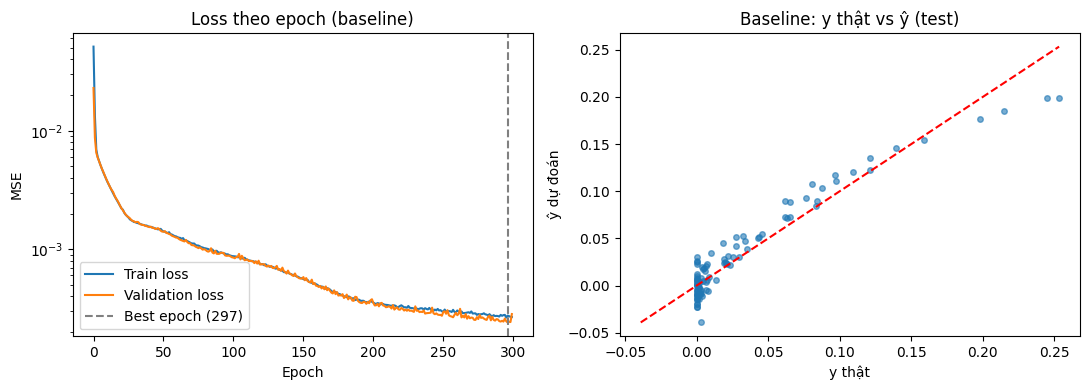

In [21]:
# Đường cong loss theo epoch (đề yêu cầu ghi lại loss theo epoch) và y thật vs ŷ trên tập test
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.train_loss, label="Train loss"); ax[0].plot(history.val_loss, label="Validation loss")
ax[0].axvline(history.best_epoch - 1, color="gray", ls="--", label=f"Best epoch ({history.best_epoch})")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE"); ax[0].set_yscale("log"); ax[0].legend(); ax[0].set_title("Loss theo epoch (baseline)")

model.eval()
with torch.no_grad():
    y_pred = model(torch.as_tensor(x_test_s, dtype=torch.float32).to(device)).cpu().numpy().reshape(-1)
ax[1].scatter(y_test.ravel(), y_pred, s=16, alpha=0.6)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
ax[1].plot([lo, hi], [lo, hi], "r--"); ax[1].set_xlabel("y thật"); ax[1].set_ylabel("ŷ dự đoán"); ax[1].set_title("Baseline: y thật vs ŷ (test)")
plt.tight_layout()
fig.savefig("figures/baseline_loss_and_pred.png", dpi=150)
plt.show()

# Giai đoạn 3: Thực nghiệm A — Quy mô dữ liệu huấn luyện

Giữ cấu hình `BASELINE` của GĐ2 (batch size **32**), chỉ đổi số mẫu A từ 200 đến 2.000.
Lấy các dòng đầu của `train_full.csv` đã sinh ngẫu nhiên ở GĐ1 để các tập nhỏ nằm trong tập lớn;
dùng cùng tập validation 400 mẫu và test 100 mẫu cho mọi lần chạy.


## 3.1. Import các thành phần và thiết lập thực nghiệm A

Sử dụng cấu hình, mô hình và bộ huấn luyện từ GĐ2. Khảo sát 10 mức dữ liệu từ 200 đến 2.000 mẫu, kiểm tra batch size 32 và danh sách ít nhất ba seed khác nhau.

In [22]:
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src.config import BASELINE
from src.data import load_csv, SPLIT_SIZES
from src.model import MLPRegressor
from src.preprocessing import fit_scaler
from src.trainer import train_model, load_best_from_history, evaluate_on_test

A_VALUES = list(range(200, 2001, 200))
assert BASELINE["batch_size"] == 32, "GĐ3 dùng batch_size=32 trong src/config.py."
assert len(set(BASELINE["seeds_for_experiments"])) >= 3
print("A:", A_VALUES)
print("Batch size:", BASELINE["batch_size"], "| Seeds:", BASELINE["seeds_for_experiments"])


A: [200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000]
Batch size: 32 | Seeds: [0, 1, 2]


## 3.2. Đọc và kiểm tra dữ liệu - `load_data_A`

Đọc các tập train, validation và test. Kiểm tra kích thước dữ liệu, bảo đảm đủ 2.000 mẫu train và giữ nguyên tập test 100 mẫu cho toàn bộ thực nghiệm.

In [23]:
def load_data_A(data_dir):
    data = {}
    for split in ("train_full", "val", "test"):
        x, y = load_csv(Path(data_dir) / f"{split}.csv")
        assert x.shape == (SPLIT_SIZES[split], 2)
        assert y.shape == (SPLIT_SIZES[split], 1)
        data[split] = (x, y)
    assert len(data["train_full"][0]) == max(A_VALUES)
    assert len(data["test"][0]) == 100
    return data


## 3.3. Huấn luyện một cấu hình - `run_single_A`

Lấy A mẫu đầu tiên từ tập train để các tập nhỏ nằm trong tập lớn. Khởi tạo mô hình mới theo seed, chuẩn hóa trên đúng A mẫu train và huấn luyện theo baseline. Khôi phục trọng số tốt nhất theo validation trước khi tính các chỉ số train và test.

In [24]:
def run_single_A(a_value, seed, data, device="cpu"):
    # Cùng seed khởi tạo cho mọi A; mỗi lần đều tạo model mới.
    torch.manual_seed(seed)
    np.random.seed(seed)
    x_full, y_full = data["train_full"]
    x_train, y_train = x_full[:a_value], y_full[:a_value]
    x_val, y_val = data["val"]
    x_test, y_test = data["test"]

    # Fit scaler riêng trên đúng A mẫu train, rồi áp dụng cho val/test.
    if BASELINE["normalize_input"]:
        scaler = fit_scaler(x_train)
        x_train, x_val, x_test = (
            scaler.transform(x) for x in (x_train, x_val, x_test)
        )

    model_A = MLPRegressor(
        input_dim=2, hidden_layers=BASELINE["hidden_layers"],
        activation=BASELINE["activation"], output_dim=1,
    )
    history_A = train_model(
        model_A, x_train, y_train, x_val, y_val,
        optimizer_name=BASELINE["optimizer"],
        learning_rate=BASELINE["learning_rate"],
        batch_size=BASELINE["batch_size"], epochs=BASELINE["epochs"],
        checkpoint_path=None, device=device, verbose=False,
    )
    model_A = load_best_from_history(model_A, history_A, device=device)
    train_metrics = evaluate_on_test(model_A, x_train, y_train, device=device)
    test_metrics = evaluate_on_test(model_A, x_test, y_test, device=device)
    result = {"A": a_value, "seed": seed}
    for split, metrics in (("train", train_metrics), ("test", test_metrics)):
        for metric in ("mse", "mae", "rmse"):
            result[f"{split}_{metric}"] = metrics[metric]
    result.update(
        best_val_loss=history_A.best_val_loss,
        best_epoch=history_A.best_epoch,
        training_time_sec=history_A.training_time_sec,
    )
    return result


## 3.4. Tổng hợp kết quả và xây dựng biểu đồ

Định nghĩa hàm tính mean và standard deviation của MSE, MAE và RMSE qua các seed. Xây dựng biểu đồ sai số train và test theo số mẫu A với thanh sai số biểu diễn độ lệch chuẩn.

In [25]:
def summarize_results_A(results):
    columns = [f"{split}_{metric}" for split in ("train", "test")
               for metric in ("mse", "mae", "rmse")]
    summary = results.groupby("A")[columns].agg(["mean", "std"])
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    return summary.reset_index()


def plot_results_A(summary, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, metric in zip(axes, ("mse", "mae", "rmse")):
        for split, color, marker in (("train", "#2878B5", "o"),
                                     ("test", "#D97924", "s")):
            ax.errorbar(
                summary["A"], summary[f"{split}_{metric}_mean"],
                yerr=summary[f"{split}_{metric}_std"],
                color=color, marker=marker, capsize=3, label=split.title(),
            )
        ax.set(xlabel="A — số mẫu huấn luyện", ylabel=metric.upper(),
               title=metric.upper(), xticks=A_VALUES)
        ax.tick_params(axis="x", labelsize=9)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
        ax.grid(True, alpha=0.25)
        ax.legend()
    fig.suptitle("Thực nghiệm A: Sai số theo số mẫu train (mean ± std qua các seed)")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 3.5. Xây dựng quy trình thực nghiệm - `run_experiment_A`

Tổ chức huấn luyện cho từng mức A và từng seed, lưu kết quả chi tiết, bảng tổng hợp và biểu đồ. Hàm `main()` cho phép chạy thực nghiệm bằng script độc lập.

In [26]:
def run_experiment_A(project_dir, device="cpu"):
    project_dir = Path(project_dir)
    assert BASELINE["batch_size"] == 32, "Cần batch_size=32 trong BASELINE."
    seeds = BASELINE["seeds_for_experiments"]
    assert len(seeds) == len(set(seeds)) and len(seeds) >= 3
    data = load_data_A(project_dir / "data")
    for folder in ("logs", "figures"):
        (project_dir / folder).mkdir(parents=True, exist_ok=True)

    results = []
    for a_value in A_VALUES:
        for seed in seeds:
            results.append(run_single_A(a_value, seed, data, device=device))
        print(f"Đã chạy A={a_value}: {len(seeds)} seed.")

    results = pd.DataFrame(results)
    summary = summarize_results_A(results)
    results.to_csv(project_dir / "logs/exp_A_results.csv", index=False)
    summary.to_csv(project_dir / "logs/exp_A_summary.csv", index=False)
    plot_results_A(summary, project_dir / "figures/exp_A_learning_curve.png")
    return results, summary


def main():
    project_dir = Path(__file__).resolve().parents[1]
    device = "cuda" if torch.cuda.is_available() else "cpu"
    _, summary = run_experiment_A(project_dir, device=device)
    print(summary.to_string(index=False))


## 3.6. Xuất script - `experiments/exp_A_samples.py`


In [27]:
# Xuất script từ các hàm vừa viết, giống cách GĐ1 xuất src/data.py.
source_A = "from pathlib import Path\nimport sys\n"
source_A += "sys.path.insert(0, str(Path(__file__).resolve().parents[1]))\n"
source_A += "import numpy as np\nimport pandas as pd\nimport torch\n"
source_A += "import matplotlib.pyplot as plt\n"
source_A += "from src.config import BASELINE\n"
source_A += "from src.data import load_csv, SPLIT_SIZES\n"
source_A += "from src.model import MLPRegressor\n"
source_A += "from src.preprocessing import fit_scaler\n"
source_A += "from src.trainer import train_model, load_best_from_history, evaluate_on_test\n\n"
source_A += f"A_VALUES = {A_VALUES!r}\n\n"
functions_A = [load_data_A, run_single_A, summarize_results_A,
               plot_results_A, run_experiment_A, main]
source_A += "\n\n".join(inspect.getsource(function) for function in functions_A)
source_A += '\n\nif __name__ == "__main__":\n    main()\n'
script_A = Path(PROJECT_DIR) / "experiments/exp_A_samples.py"
script_A.parent.mkdir(parents=True, exist_ok=True)
script_A.write_text(source_A, encoding="utf-8")
print("Đã lưu:", script_A)


Đã lưu: /content/Gaussian2D/experiments/exp_A_samples.py


## 3.7. Chạy thực nghiệm A

Thực hiện 10 mức dữ liệu × 3 seed với cùng cấu hình baseline.

Đã chạy A=200: 3 seed.
Đã chạy A=400: 3 seed.
Đã chạy A=600: 3 seed.
Đã chạy A=800: 3 seed.
Đã chạy A=1000: 3 seed.
Đã chạy A=1200: 3 seed.
Đã chạy A=1400: 3 seed.
Đã chạy A=1600: 3 seed.
Đã chạy A=1800: 3 seed.
Đã chạy A=2000: 3 seed.


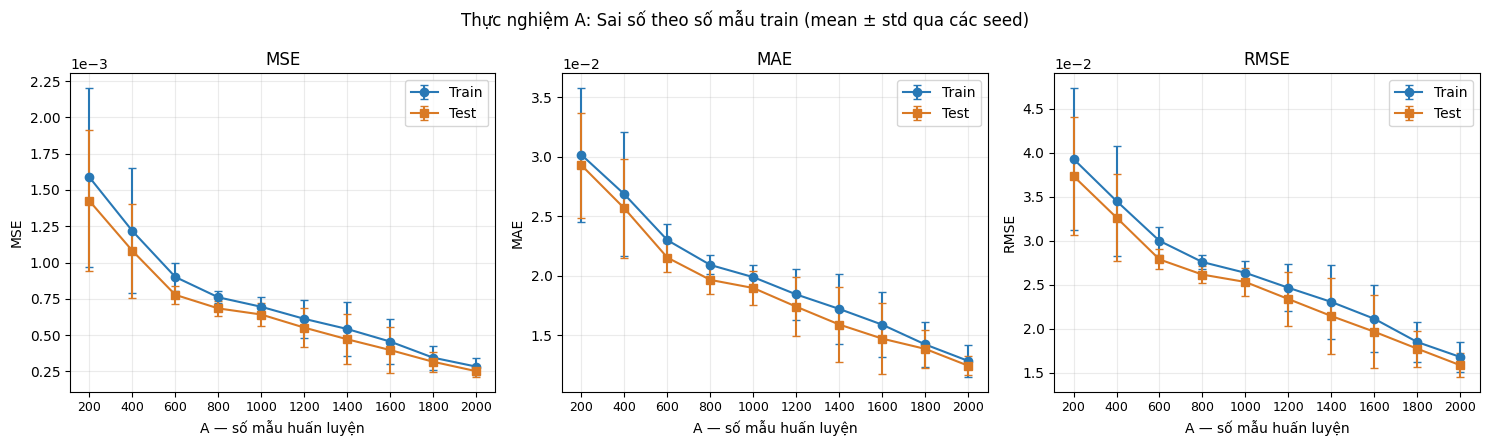

In [28]:
# Chạy 10 mốc A × 3 seed, dùng nguyên số epoch và cấu hình của GĐ2.
df_A, summary_A = run_experiment_A(PROJECT_DIR, device=str(device))


## 3.8. Trình bày bảng kết quả mean ± std

Hiển thị MSE, MAE và RMSE trên train và test dưới dạng trung bình ± độ lệch chuẩn theo từng mức A để phục vụ nhận xét và bàn giao báo cáo.

In [29]:
# Bảng mean ± std để bàn giao cho Cao Sơn.
table_A = pd.DataFrame({"A": summary_A["A"]})
for split in ("train", "test"):
    for metric in ("mse", "mae", "rmse"):
        means = summary_A[f"{split}_{metric}_mean"]
        stds = summary_A[f"{split}_{metric}_std"]
        table_A[f"{split.title()} {metric.upper()}"] = [
            f"{mean:.6f} ± {std:.6f}" for mean, std in zip(means, stds)
        ]
table_A


,A,Train MSE,Train MAE,Train RMSE,Test MSE,Test MAE,Test RMSE
0,200,0.001587 ± 0.000615,0.030155 ± 0.005619,0.039292 ± 0.008089,0.001425 ± 0.000486,0.029282 ± 0.004385,0.037344 ± 0.006734
1,400,0.001217 ± 0.000431,0.026842 ± 0.005213,0.034516 ± 0.006256,0.001081 ± 0.000322,0.025659 ± 0.004138,0.032631 ± 0.004943
2,600,0.000900 ± 0.000095,0.022994 ± 0.001373,0.029980 ± 0.001586,0.000777 ± 0.000063,0.021530 ± 0.001206,0.027868 ± 0.001144
3,800,0.000760 ± 0.000042,0.020913 ± 0.000795,0.027569 ± 0.000761,0.000684 ± 0.000053,0.019660 ± 0.001180,0.026141 ± 0.001009
4,1000,0.000695 ± 0.000071,0.019889 ± 0.000991,0.026343 ± 0.001343,0.000642 ± 0.000081,0.018979 ± 0.001411,0.025302 ± 0.001624
5,1200,0.000612 ± 0.000129,0.018439 ± 0.002125,0.024645 ± 0.002700,0.000552 ± 0.000136,0.017410 ± 0.002457,0.023361 ± 0.003030
6,1400,0.000542 ± 0.000185,0.017223 ± 0.002906,0.023031 ± 0.004202,0.000471 ± 0.000173,0.015915 ± 0.003172,0.021430 ± 0.004271
7,1600,0.000456 ± 0.000156,0.015902 ± 0.002714,0.021115 ± 0.003818,0.000397 ± 0.000160,0.014731 ± 0.002983,0.019641 ± 0.004161
8,1800,0.000345 ± 0.000083,0.014244 ± 0.001916,0.018470 ± 0.002317,0.000316 ± 0.000070,0.013870 ± 0.001587,0.017712 ± 0.002030
9,2000,0.000283 ± 0.000057,0.012862 ± 0.001376,0.016769 ± 0.001756,0.000252 ± 0.000042,0.012459 ± 0.000816,0.015831 ± 0.001372


## 3.9. Kiểm tra đầu ra và nhận xét xu hướng

Kiểm tra đủ 10 mức A, đủ số lần chạy theo seed, không có kết quả trùng hoặc giá trị thiếu/vô hạn và đầy đủ các file đầu ra. Đối chiếu sai số khi tăng số mẫu, đồng thời lưu ý rằng cùng số epoch thì tập train lớn hơn cũng tạo ra nhiều bước cập nhật hơn.

In [30]:
assert sorted(df_A["A"].unique()) == A_VALUES
assert len(df_A) == len(A_VALUES) * len(BASELINE["seeds_for_experiments"])
assert not df_A.duplicated(["A", "seed"]).any()
assert np.isfinite(df_A.select_dtypes(include="number").to_numpy()).all()
for filename in ("experiments/exp_A_samples.py", "logs/exp_A_results.csv",
                 "logs/exp_A_summary.csv", "figures/exp_A_learning_curve.png"):
    path_A = Path(PROJECT_DIR) / filename
    assert path_A.is_file() and path_A.stat().st_size > 0
    print("OK:", filename)

mse_A = summary_A["test_mse_mean"].to_numpy()
print(f"Test MSE trung bình: A=200 → {mse_A[0]:.6f}; A=2000 -> {mse_A[-1]:.6f}.")
print(f"Có {int((np.diff(mse_A) < 0).sum())}/9 bước tăng A làm Test MSE giảm.")
print("Sai số không nhất thiết giảm ở mọi mốc; xem thêm độ lệch chuẩn giữa các seed.")
print("Cùng số epoch, A lớn cũng có nhiều bước cập nhật hơn, xu hướng phản ánh cả hai yếu tố.")


OK: experiments/exp_A_samples.py
OK: logs/exp_A_results.csv
OK: logs/exp_A_summary.csv
OK: figures/exp_A_learning_curve.png
Test MSE trung bình: A=200 → 0.001425; A=2000 -> 0.000252.
Có 9/9 bước tăng A làm Test MSE giảm.
Sai số không nhất thiết giảm ở mọi mốc; xem thêm độ lệch chuẩn giữa các seed.
Cùng số epoch, A lớn cũng có nhiều bước cập nhật hơn, xu hướng phản ánh cả hai yếu tố.


## 9. `experiments/exp_B_width.py` — Thực nghiệm B (GĐ4)

Khảo sát MLP **1 tầng ẩn** với `B = 1..10` và mở rộng `16, 32, 64` (đúng kế hoạch nhóm), cố định mọi thứ khác theo `BASELINE`, chạy 3 seed để báo cáo mean ± std. Với mỗi (B, seed): train, **nạp lại trọng số tốt nhất theo validation**, rồi đo train/test MSE và MAE. Test chỉ dùng để đo cuối, không dùng chọn cấu hình.

Script ghi `logs/exp_B_results.csv` (từng lần chạy), `logs/exp_B_summary.csv` (mean ± std theo B), `figures/exp_B_width_curve.png` và `figures/exp_B_best_pred_vs_true.png`.

In [31]:
%%writefile experiments/exp_B_width.py
"""
experiments/exp_B_width.py
----------------------------
Giai doan 4 - Thuc nghiem B: khao sat anh huong cua DO RONG mang (so no-ron
trong 1 tang an) len sai so xap xi, voi so luong mau huan luyen va so tang
an duoc GIU CO DINH (chi doi B).

Doc du lieu that qua src/data.py cua Trung Hieu (Giai doan 1):
    from src.data import load_csv
    x, y = load_csv(path)   -> x shape (N,2), y shape (N,1)

File nay CHUA DUOC CHAY THAT voi du lieu that, dung theo yeu cau cua
Thanh Phuong: "Chỉ viết code hoàn chỉnh, chưa cần chạy thật — đợi Trung Hiếu
giao CSV rồi chạy một lần luôn". Mot ban kiem thu rieng (smoke test voi du
lieu gia lap, KHONG phai ket qua chinh thuc) duoc dat o
`experiments/_smoke_test_exp_B.py`.

Cach chay (sau khi co du lieu that trong data/train_full.csv, data/val.csv,
data/test.csv):
    python -m experiments.exp_B_width
"""

import os
import sys

# Cho phep chay truc tiep "python experiments/exp_B_width.py" tu thu muc goc du an
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))

import numpy as np
import pandas as pd

from src.config import BASELINE
from src.model import MLPRegressor
from src.preprocessing import fit_scaler
from src.trainer import train_model, evaluate_on_test, load_best_from_history

# ----- Cac gia tri B (so no-ron trong 1 tang an) can khao sat -----
B_VALUES = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 16, 32, 64]

DATA_DIR = "data"
LOGS_DIR = "logs"
FIGURES_DIR = "figures"


def _load_split(filename: str):
    """
    Doc 1 file CSV du lieu that qua src.data.load_csv cua Trung Hieu.
    Tach rieng de bao loi ro rang (bang tieng Viet) neu src/data.py
    hoac file CSV chua ton tai, thay vi mot traceback kho hieu.
    """
    try:
        from src.data import load_csv
    except ImportError as exc:
        raise ImportError(
            "Chưa tìm thấy src/data.py (phần của Trung Hiếu - Giai đoạn 1). "
            "Hãy chắc chắn file này đã được thêm vào thư mục src/ trước khi "
            "chạy Thực nghiệm B."
        ) from exc

    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy '{path}'. Thực nghiệm B cần dữ liệu thật do "
            f"Trung Hiếu cung cấp (data/train_full.csv, data/val.csv, data/test.csv)."
        )
    x, y = load_csv(path)
    return np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64).reshape(-1)


def load_all_data():
    """Doc ca 3 tap train_full / val / test theo dung quy uoc ten file cua nhom."""
    x_train, y_train = _load_split("train_full.csv")
    x_val, y_val = _load_split("val.csv")
    x_test, y_test = _load_split("test.csv")
    return x_train, y_train, x_val, y_val, x_test, y_test


def run_single(b_value: int, seed: int, data: dict, device: str = "cpu") -> dict:
    """
    Train MOT cau hinh (b_value, seed) cu the, theo dung cau hinh BASELINE
    chi thay doi hidden_layers = [b_value]. Khong luu checkpoint (checkpoint_path=None)
    vi day la mot sweep kham pha sieu tham so, khong phai buoc chon mo hinh cuoi cung.
    """
    import torch

    torch.manual_seed(seed)
    np.random.seed(seed)

    x_train, y_train = data["x_train"], data["y_train"]
    x_val, y_val = data["x_val"], data["y_val"]
    x_test, y_test = data["x_test"], data["y_test"]

    # Chuẩn hóa đầu vào: fit CHỈ trên train, áp dụng lại cho val/test (tránh leakage)
    if BASELINE["normalize_input"]:
        scaler = fit_scaler(x_train)
        x_train_in = scaler.transform(x_train)
        x_val_in = scaler.transform(x_val)
        x_test_in = scaler.transform(x_test)
    else:
        x_train_in, x_val_in, x_test_in = x_train, x_val, x_test

    model = MLPRegressor(
        input_dim=x_train.shape[1],
        hidden_layers=[b_value],
        activation=BASELINE["activation"],
        output_dim=1,
    )

    history = train_model(
        model,
        x_train_in, y_train,
        x_val_in, y_val,
        optimizer_name=BASELINE["optimizer"],
        learning_rate=BASELINE["learning_rate"],
        batch_size=BASELINE["batch_size"],
        epochs=BASELINE["epochs"],
        checkpoint_path=None,
        device=device,
        verbose=False,
    )

    # QUAN TRỌNG: đánh giá bằng trọng số của EPOCH TỐT NHẤT theo validation
    # loss (lấy từ RAM qua history.best_state_dict), KHÔNG phải trọng số của
    # epoch cuối cùng — đúng yêu cầu đề bài "checkpoint mô hình tốt nhất theo
    # validation loss" dùng để đánh giá/dự đoán (mục 3.2 và tiêu chí chấm
    # điểm "validation/checkpoint và dự đoán/đánh giá").
    model = load_best_from_history(model, history, device=device)

    train_metrics = evaluate_on_test(model, x_train_in, y_train, device=device)
    test_metrics = evaluate_on_test(model, x_test_in, y_test, device=device)

    import torch as _torch
    model.eval()
    with _torch.no_grad():
        y_test_pred = model(_torch.as_tensor(x_test_in, dtype=_torch.float32).to(device)).cpu().numpy().reshape(-1)

    metrics = {
        "B": b_value,
        "seed": seed,
        "train_mse": train_metrics["mse"],
        "train_mae": train_metrics["mae"],
        "test_mse": test_metrics["mse"],
        "test_mae": test_metrics["mae"],
        "best_val_loss": history.best_val_loss,
        "best_epoch": history.best_epoch,
        "training_time_sec": history.training_time_sec,
    }
    return metrics, y_test_pred


def main(device: str = "cpu"):
    os.makedirs(LOGS_DIR, exist_ok=True)
    os.makedirs(FIGURES_DIR, exist_ok=True)

    x_train, y_train, x_val, y_val, x_test, y_test = load_all_data()
    data = {
        "x_train": x_train, "y_train": y_train,
        "x_val": x_val, "y_val": y_val,
        "x_test": x_test, "y_test": y_test,
    }

    results = []
    predictions_cache = {}  # (B, seed) -> y_test_pred, dùng để vẽ y-ŷ cho cấu hình tốt nhất
    for b_value in B_VALUES:
        for seed in BASELINE["seeds_for_experiments"]:
            print(f">> Đang chạy B={b_value}, seed={seed} ...")
            metrics, y_test_pred = run_single(b_value, seed, data, device=device)
            results.append(metrics)
            predictions_cache[(b_value, seed)] = y_test_pred

    df = pd.DataFrame(results)
    csv_path = os.path.join(LOGS_DIR, "exp_B_results.csv")
    df.to_csv(csv_path, index=False)
    print(f"\nĐã lưu kết quả chi tiết: {csv_path}")

    summary = df.groupby("B").agg(
        train_mse_mean=("train_mse", "mean"), train_mse_std=("train_mse", "std"),
        test_mse_mean=("test_mse", "mean"), test_mse_std=("test_mse", "std"),
        train_mae_mean=("train_mae", "mean"), test_mae_mean=("test_mae", "mean"),
    ).reset_index()
    summary_path = os.path.join(LOGS_DIR, "exp_B_summary.csv")
    summary.to_csv(summary_path, index=False)
    print(f"Đã lưu bảng tổng hợp (mean +- std theo B): {summary_path}\n")
    print(summary.to_string(index=False))

    _plot_results(summary)

    # Trực quan hóa y thật–ŷ dự đoán (yêu cầu mục 3.2 + tiêu chí "Đánh giá & phân tích chung")
    # cho cấu hình B có test_mse trung bình thấp nhất, dùng seed đầu tiên trong danh sách.
    best_b = int(summary.loc[summary["test_mse_mean"].idxmin(), "B"])
    best_seed = BASELINE["seeds_for_experiments"][0]
    from src.plotting import plot_pred_vs_true
    plot_pred_vs_true(
        data["y_test"], predictions_cache[(best_b, best_seed)],
        title=f"Thực nghiệm B — y thật vs ŷ dự đoán (B={best_b} tốt nhất, seed={best_seed})",
        save_path=os.path.join(FIGURES_DIR, "exp_B_best_pred_vs_true.png"),
    )
    print(f"Đã lưu biểu đồ y-ŷ cho cấu hình tốt nhất (B={best_b}): "
          f"{os.path.join(FIGURES_DIR, 'exp_B_best_pred_vs_true.png')}")

    return df, summary


def _plot_results(summary: "pd.DataFrame"):
    """Ve bieu do sai so (train & test MSE) theo B, co errorbar the hien std qua cac seed."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.errorbar(
        summary["B"], summary["train_mse_mean"], yerr=summary["train_mse_std"],
        marker="o", capsize=3, label="Train MSE",
    )
    ax.errorbar(
        summary["B"], summary["test_mse_mean"], yerr=summary["test_mse_std"],
        marker="s", capsize=3, label="Test MSE",
    )
    ax.set_xlabel("B - số nơ-ron trong tầng ẩn (độ rộng mạng)")
    ax.set_ylabel("MSE")
    ax.set_title("Thực nghiệm B: Sai số theo độ rộng mạng (MLP 1 tầng ẩn)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()

    fig_path = os.path.join(FIGURES_DIR, "exp_B_width_curve.png")
    fig.savefig(fig_path, dpi=150)
    plt.close(fig)
    print(f"Đã lưu biểu đồ: {fig_path}")


if __name__ == "__main__":
    main()

Writing experiments/exp_B_width.py


## 10. Chạy Thực nghiệm B (khoảng 7–8 phút trên CPU)

Chạy toàn bộ 13 giá trị B × 3 seed × 300 epoch.

In [32]:
import experiments.exp_B_width as expB
importlib.reload(expB)
df_B, summary_B = expB.main(device=str(device))

>> Đang chạy B=1, seed=0 ...
>> Đang chạy B=1, seed=1 ...
>> Đang chạy B=1, seed=2 ...
>> Đang chạy B=2, seed=0 ...
>> Đang chạy B=2, seed=1 ...
>> Đang chạy B=2, seed=2 ...
>> Đang chạy B=3, seed=0 ...
>> Đang chạy B=3, seed=1 ...
>> Đang chạy B=3, seed=2 ...
>> Đang chạy B=4, seed=0 ...
>> Đang chạy B=4, seed=1 ...
>> Đang chạy B=4, seed=2 ...
>> Đang chạy B=5, seed=0 ...
>> Đang chạy B=5, seed=1 ...
>> Đang chạy B=5, seed=2 ...
>> Đang chạy B=6, seed=0 ...
>> Đang chạy B=6, seed=1 ...
>> Đang chạy B=6, seed=2 ...
>> Đang chạy B=7, seed=0 ...
>> Đang chạy B=7, seed=1 ...
>> Đang chạy B=7, seed=2 ...
>> Đang chạy B=8, seed=0 ...
>> Đang chạy B=8, seed=1 ...
>> Đang chạy B=8, seed=2 ...
>> Đang chạy B=9, seed=0 ...
>> Đang chạy B=9, seed=1 ...
>> Đang chạy B=9, seed=2 ...
>> Đang chạy B=10, seed=0 ...
>> Đang chạy B=10, seed=1 ...
>> Đang chạy B=10, seed=2 ...
>> Đang chạy B=16, seed=0 ...
>> Đang chạy B=16, seed=1 ...
>> Đang chạy B=16, seed=2 ...
>> Đang chạy B=32, seed=0 ...
>> Đang

In [33]:
# Bảng số liệu chi tiết bàn giao cho Cao Sơn (mean ± std theo B)
import pandas as pd
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
summary_B

,B,train_mse_mean,train_mse_std,test_mse_mean,test_mse_std,train_mae_mean,test_mae_mean
0,1,0.003242,0.000002,0.002875,0.000003,0.040767,0.038337
1,2,0.001662,0.000078,0.001437,0.000058,0.024812,0.022746
2,3,0.001173,0.000471,0.001147,0.000341,0.022845,0.023213
3,4,0.000747,0.000164,0.000666,0.000201,0.019642,0.018472
4,5,0.000525,0.000164,0.000472,0.000175,0.017392,0.016318
5,6,0.000483,0.000143,0.000449,0.000100,0.016786,0.016183
6,7,0.000370,0.000245,0.000353,0.000200,0.014450,0.013879
7,8,0.000283,0.000057,0.000252,0.000042,0.012862,0.012459
8,9,0.000374,0.000372,0.000345,0.000308,0.013502,0.012791
9,10,0.000282,0.000009,0.000271,0.000030,0.013016,0.012210


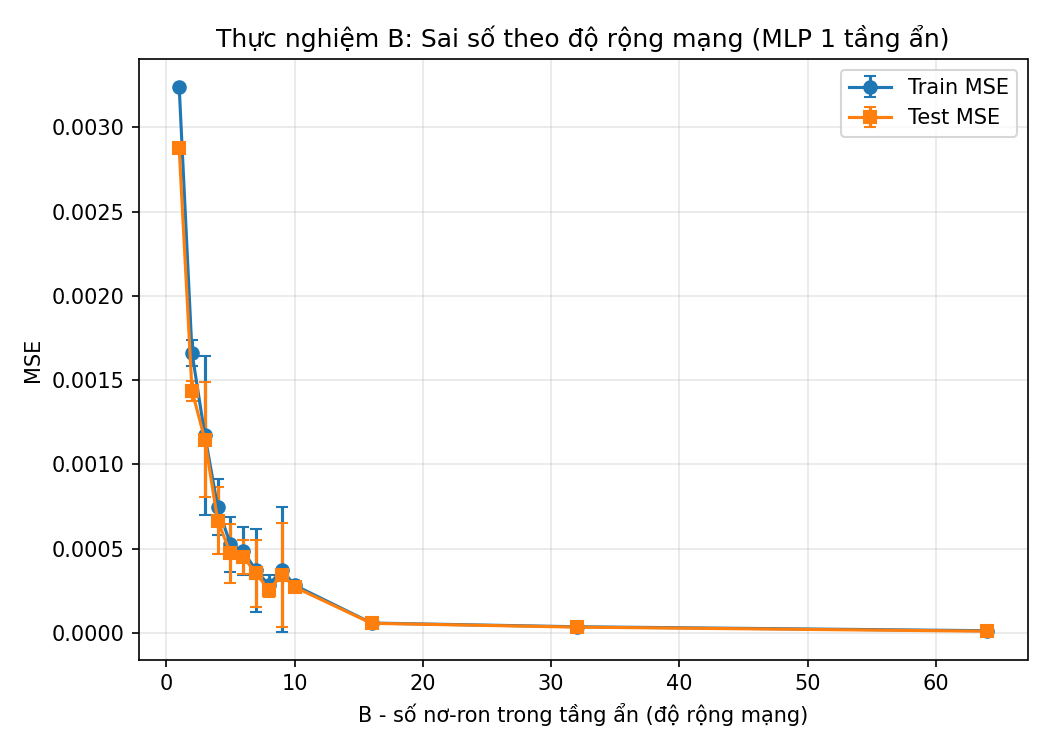

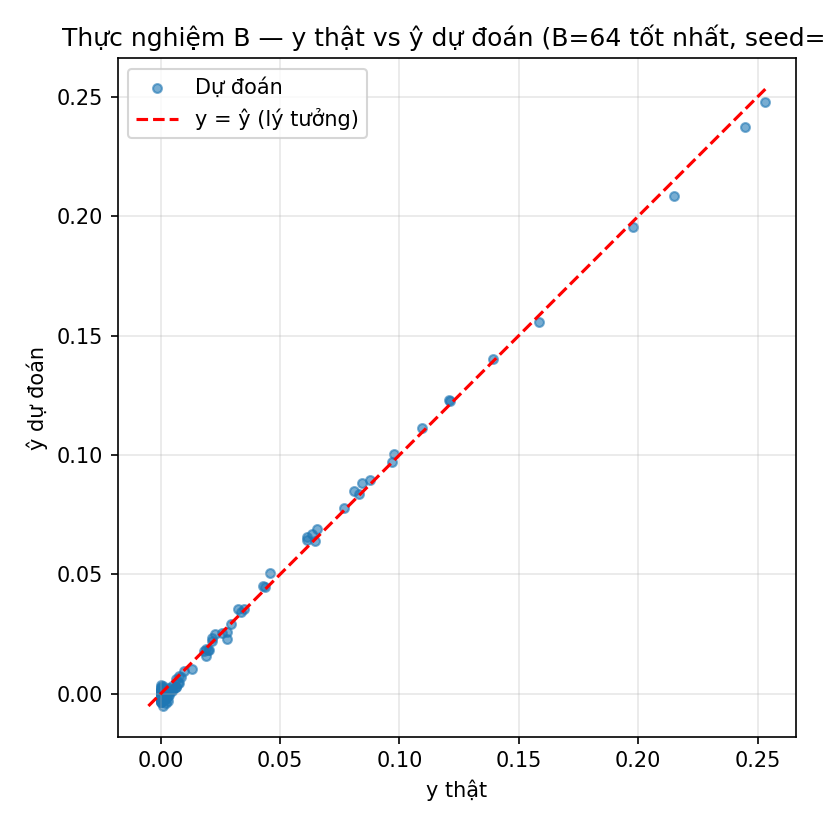

In [34]:
from IPython.display import Image, display
display(Image("figures/exp_B_width_curve.png"))
display(Image("figures/exp_B_best_pred_vs_true.png"))

## 11. Kiểm tra nghiệm thu và bàn giao

Cell dưới kiểm tra mọi sản phẩm trong bảng kế hoạch đã được tạo ra từ chính code ở trên.

In [35]:
required = {
    "GĐ2": ["src/model.py", "src/trainer.py", "src/metrics.py", "checkpoints/best_model.pt"],
    "GĐ4": ["experiments/exp_B_width.py", "logs/exp_B_results.csv", "logs/exp_B_summary.csv", "figures/exp_B_width_curve.png"],
}
for stage, paths in required.items():
    for p in paths:
        ok = Path(p).exists() and Path(p).stat().st_size > 0
        print(f"[{'OK' if ok else 'THIẾU'}] {stage}: {p}")
        assert ok, p
res = pd.read_csv("logs/exp_B_results.csv")
assert sorted(res["B"].unique()) == [1,2,3,4,5,6,7,8,9,10,16,32,64] and res["seed"].nunique() >= 3
print("\nSố mốc B:", res["B"].nunique(), "| số seed:", res["seed"].nunique(), "| tổng số lần chạy:", len(res))

[OK] GĐ2: src/model.py
[OK] GĐ2: src/trainer.py
[OK] GĐ2: src/metrics.py
[OK] GĐ2: checkpoints/best_model.pt
[OK] GĐ4: experiments/exp_B_width.py
[OK] GĐ4: logs/exp_B_results.csv
[OK] GĐ4: logs/exp_B_summary.csv
[OK] GĐ4: figures/exp_B_width_curve.png

Số mốc B: 13 | số seed: 3 | tổng số lần chạy: 39


**Bàn giao:**
- Cho **Trung Hiếu và Cao Sơn** (GĐ2): `src/model.py`, `src/trainer.py`, `src/metrics.py` (cộng `src/config.py`, `src/preprocessing.py`) để `import` và chạy thực nghiệm A, C; checkpoint mẫu `checkpoints/best_model.pt`.
- Cho **Cao Sơn** (GĐ4): `logs/exp_B_summary.csv`, `logs/exp_B_results.csv`, `figures/exp_B_width_curve.png` để đưa vào báo cáo và slide.
- Trước khi nộp cần cả nhóm chốt baseline duy nhất (nhất là `batch_size`), vì A/B/C phải dùng chung.